# Penyelesaian 5 Studi Kasus Geofisika

**Nama:** Muhammad Fikri Aliyuddin
**NIM:** H061241051
**Kelas:** AI, Kelas C

Notebook ini menyelesaikan lima kasus dari prompt sebelumnya. Setiap kasus memakai urutan yang sama: **ringkasan masalah, asumsi, langkah penyelesaian (kode), tabel hasil, interpretasi, dan verifikasi.** Semua angka dihitung oleh kode, bukan diketik manual.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda v: f"{v:.4g}")

---
# Kasus 1: Seismik Refraksi Dua Lapis

## Ringkasan masalah
Dari kurva waktu-jarak satu titik tembak, tentukan V1, V2, waktu intercept (ti), jarak crossover (xc), dan ketebalan lapisan 1 (h1).

## Asumsi
- Model dua lapisan dengan bidang batas datar dan V2 > V1.
- Titik data dipisah menjadi dua segmen: gelombang langsung (dekat sumber) dan gelombang refraksi (jauh).
- Titik pemisah dicari secara objektif, yaitu yang memberi galat kuadrat total paling kecil untuk dua garis lurus.

## Rumus
- Gelombang langsung: $t = x / V_1$
- Gelombang refraksi: $t = t_i + x / V_2$
- Crossover: $x_c = \dfrac{t_i}{\;1/V_1 - 1/V_2\;}$
- Ketebalan via intercept: $h_1 = \dfrac{t_i \, V_1 V_2}{2\sqrt{V_2^2 - V_1^2}}$
- Ketebalan via crossover: $h_1 = \dfrac{x_c}{2}\sqrt{\dfrac{V_2 - V_1}{V_2 + V_1}}$

In [2]:
x = np.array([5, 10, 15, 20, 30, 40, 50, 60], dtype=float)           # m
t = np.array([12.5, 25.0, 33.6, 36.7, 43.0, 49.2, 55.5, 61.7]) / 1000  # ms -> s

# Cari titik pemisah: n titik pertama = langsung (garis lewat titik asal),
# sisanya = refraksi (garis bebas). Pilih n dengan SSE terkecil.
best = None
for n in range(2, len(x) - 1):          # minimal 2 titik tiap segmen
    xd, td = x[:n], t[:n]
    s_d = np.sum(xd * td) / np.sum(xd**2)            # kemiringan lewat titik asal
    sse_d = np.sum((td - s_d * xd) ** 2)
    xr, tr = x[n:], t[n:]
    s_r, ti_r = np.polyfit(xr, tr, 1)
    sse_r = np.sum((tr - (s_r * xr + ti_r)) ** 2)
    if best is None or sse_d + sse_r < best[0]:
        best = (sse_d + sse_r, n, s_d, s_r, ti_r)

_, n_dir, slope_d, slope_r, ti = best
V1 = 1 / slope_d
V2 = 1 / slope_r
xc = ti / (1 / V1 - 1 / V2)
h1_ti = ti * V1 * V2 / (2 * np.sqrt(V2**2 - V1**2))
h1_xc = (xc / 2) * np.sqrt((V2 - V1) / (V2 + V1))

print(f"Titik gelombang langsung : x = {x[:n_dir]} m")
print(f"Titik gelombang refraksi : x = {x[n_dir:]} m")

Titik gelombang langsung : x = [ 5. 10.] m
Titik gelombang refraksi : x = [15. 20. 30. 40. 50. 60.] m


In [3]:
hasil1 = pd.DataFrame({
    "Besaran": ["V1", "V2", "ti", "xc", "h1 (metode ti)", "h1 (metode xc)"],
    "Nilai":   [V1, V2, ti * 1000, xc, h1_ti, h1_xc],
    "Satuan":  ["m/s", "m/s", "ms", "m", "m", "m"],
})
hasil1

,Besaran,Nilai,Satuan
0,V1,400,m/s
1,V2,1600,m/s
2,ti,24.22,ms
3,xc,12.92,m
4,h1 (metode ti),5.004,m
5,h1 (metode xc),5.004,m


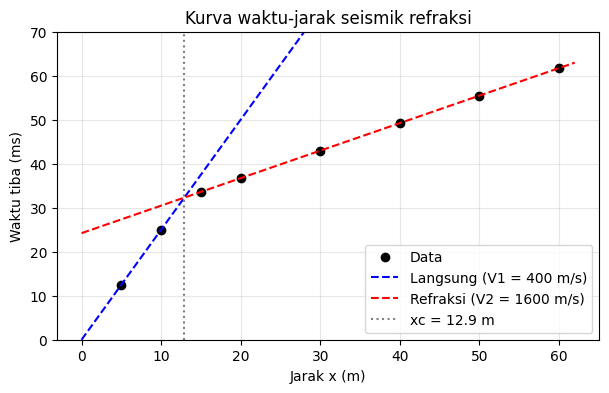

In [4]:
xx = np.linspace(0, 62, 200)
plt.figure(figsize=(7, 4))
plt.plot(x, t * 1000, "ko", label="Data")
plt.plot(xx, xx / V1 * 1000, "b--", label=f"Langsung (V1 = {V1:.0f} m/s)")
plt.plot(xx, (ti + xx / V2) * 1000, "r--", label=f"Refraksi (V2 = {V2:.0f} m/s)")
plt.axvline(xc, color="gray", ls=":", label=f"xc = {xc:.1f} m")
plt.xlabel("Jarak x (m)"); plt.ylabel("Waktu tiba (ms)")
plt.title("Kurva waktu-jarak seismik refraksi"); plt.legend(); plt.grid(alpha=.3)
plt.ylim(0, 70); plt.show()

## Interpretasi geofisika
Lapisan 1 punya kecepatan sekitar 400 m/s, yang cocok dengan tanah lapuk, pasir lepas, atau material kering tak terkonsolidasi. Lapisan 2 sekitar 1600 m/s, yang cocok dengan material lebih padat atau jenuh air, seperti lempung keras, kerikil jenuh, atau batuan lapuk. Lapisan keras berada pada kedalaman sekitar 5 m, sehingga relevan untuk pondasi dangkal.

## Verifikasi

In [5]:
# 1. Hitung ulang waktu tiba prediksi untuk 2 titik (x=10 langsung, x=40 refraksi)
for xi in (10, 40):
    t_pred = xi / V1 if xi < xc else ti + xi / V2
    t_obs = t[list(x).index(xi)]
    print(f"x={xi:>2} m  prediksi={t_pred*1000:.2f} ms  data={t_obs*1000:.2f} ms  selisih={abs(t_pred-t_obs)*1000:.2f} ms")

# 2. Bandingkan h1 dari dua metode
print(f"\nh1 (ti) = {h1_ti:.3f} m | h1 (xc) = {h1_xc:.3f} m | selisih = {abs(h1_ti-h1_xc):.4f} m")

# 3. Cek rentang kecepatan geologi umum
assert 200 < V1 < 1000 and 1000 < V2 < 6000
assert V2 > V1 and xc > x[n_dir - 1] and h1_ti > 0
print("Satuan waktu dikonversi ms -> s, V2 > V1, dan nilai masuk rentang geologi umum: OK")

x=10 m  prediksi=25.00 ms  data=25.00 ms  selisih=0.00 ms
x=40 m  prediksi=49.22 ms  data=49.20 ms  selisih=0.02 ms

h1 (ti) = 5.004 m | h1 (xc) = 5.004 m | selisih = 0.0000 m
Satuan waktu dikonversi ms -> s, V2 > V1, dan nilai masuk rentang geologi umum: OK


Selisih h1 dari dua metode sangat kecil. Keduanya diturunkan dari model dan parameter yang sama, sehingga seharusnya hampir identik. Selisih sisa hanya berasal dari pembulatan. Perlu dicatat bahwa V1 dan V2 dihitung dari regresi, jadi nilainya bisa sedikit berbeda dari hitungan tangan yang memakai dua titik saja.

---
# Kasus 2: Anomali Bouguer Lengkap

## Ringkasan masalah
Hitung gravitasi normal, koreksi Free-Air, anomali Free-Air, koreksi Bouguer, dan anomali Bouguer lengkap (CBA) di satu stasiun.

## Asumsi
- Gravitasi normal memakai rumus **GRS80** (bentuk tertutup, Somigliana).
- $g_{obs}$ sudah dikoreksi drift dan pasang surut.
- Bouguer berupa pelat tak hingga dengan densitas reduksi 2.67 g/cm³. Koreksi medan sudah diberikan (0.80 mGal).
- Lintang selatan: nilai $\sin^2\varphi$ sama dengan lintang utara pada besar sudut yang sama.

## Rumus
- $g_n = 978032.67715\,\dfrac{1 + 0.001931851353\sin^2\varphi}{\sqrt{1 - 0.0066943800229\sin^2\varphi}}$ (mGal)
- $FAC = 0.3086\,h$ (positif, karena stasiun di atas datum)
- $BC = 0.04193\,\rho\,h$ (dengan $\rho$ dalam g/cm³ dan $h$ dalam m; **dikurangkan**)
- $FAA = g_{obs} - g_n + FAC$
- $CBA = g_{obs} - g_n + FAC - BC + TC$

In [6]:
g_obs = 978085.00      # mGal
lat = 5.0              # derajat LS
h = 120.0              # m
rho = 2.67             # g/cm3
TC = 0.80              # mGal
grad_FA = 0.3086       # mGal/m

s2 = np.sin(np.radians(lat)) ** 2
g_n = 978032.67715 * (1 + 0.001931851353 * s2) / np.sqrt(1 - 0.0066943800229 * s2)
FAC = grad_FA * h
FAA = g_obs - g_n + FAC
BC = 0.04193 * rho * h
CBA = g_obs - g_n + FAC - BC + TC

hasil2 = pd.DataFrame({
    "Besaran": ["Gravitasi normal (GRS80)", "Koreksi Free-Air (FAC)", "Anomali Free-Air (FAA)",
                "Koreksi Bouguer (BC)", "Koreksi medan (TC)", "Anomali Bouguer Lengkap (CBA)"],
    "Nilai (mGal)": [g_n, FAC, FAA, BC, TC, CBA],
})
hasil2.style.format({"Nilai (mGal)": "{:.2f}"}).hide(axis="index")

Besaran,Nilai (mGal)
Gravitasi normal (GRS80),978071.90
Koreksi Free-Air (FAC),37.03
Anomali Free-Air (FAA),50.13
Koreksi Bouguer (BC),13.43
Koreksi medan (TC),0.80
Anomali Bouguer Lengkap (CBA),37.50


## Interpretasi geofisika
CBA bernilai positif, sekitar +37.5 mGal. Setelah semua pengaruh ketinggian dan topografi dibuang, stasiun ini masih lebih tinggi dari nilai normalnya. Ini menunjukkan massa berdensitas lebih besar dari 2.67 g/cm³ di bawah permukaan, misalnya batuan dasar yang dangkal, intrusi, atau kerak yang menipis. Satu titik saja belum cukup untuk menyimpulkan bentuk struktur. Interpretasi yang baik butuh peta CBA dari banyak stasiun.

## Verifikasi

In [7]:
# Jalur alternatif: CBA = FAA - BC + TC
CBA_alt = FAA - BC + TC
print(f"CBA (langsung)  = {CBA:.4f} mGal")
print(f"CBA (FAA-BC+TC) = {CBA_alt:.4f} mGal")
assert np.isclose(CBA, CBA_alt)

# Tanda dan orde besar koreksi
assert FAC > 0 and BC > 0 and TC > 0       # BC dikurangkan, FAC & TC ditambahkan
print(f"FAC = {FAC:.2f} mGal (~0.31 mGal/m x 120 m), BC = {BC:.2f} mGal (~0.112 mGal/m x 120 m)")
print("Tanda koreksi dan besar koreksi wajar untuk h = 120 m: OK")

CBA (langsung)  = 37.4998 mGal
CBA (FAA-BC+TC) = 37.4998 mGal
FAC = 37.03 mGal (~0.31 mGal/m x 120 m), BC = 13.43 mGal (~0.112 mGal/m x 120 m)
Tanda koreksi dan besar koreksi wajar untuk h = 120 m: OK


---
# Kasus 3: Geolistrik Wenner

## Ringkasan masalah
Hitung faktor geometri K dan resistivitas semu $\rho_a$ untuk lima spasi elektroda, lalu interpretasikan pola kurvanya secara kualitatif.

## Asumsi
- Konfigurasi Wenner dengan spasi seragam $a$, sounding vertikal satu titik.
- Medium diperlakukan sebagai setengah ruang untuk menghitung $\rho_a$.
- Interpretasi hanya kualitatif, tanpa inversi.

## Rumus
- $K = 2\pi a$
- $R = \Delta V / I$ (mV dibagi mA langsung menghasilkan Ω)
- $\rho_a = K\,R$

In [8]:
a = np.array([2, 4, 8, 16, 32], dtype=float)      # m
dV = np.array([180, 110, 60, 40, 30], dtype=float) # mV
I = np.array([200] * 5, dtype=float)               # mA

R = (dV * 1e-3) / (I * 1e-3)      # ohm (konversi eksplisit mV->V, mA->A)
K = 2 * np.pi * a                 # m
rho_a = K * R                     # ohm.m

hasil3 = pd.DataFrame({"a (m)": a, "K (m)": K, "R = dV/I (ohm)": R, "rho_a (ohm.m)": rho_a})
hasil3.style.format({"K (m)": "{:.2f}", "R = dV/I (ohm)": "{:.3f}", "rho_a (ohm.m)": "{:.2f}"}).hide(axis="index")

a (m),K (m),R = dV/I (ohm),rho_a (ohm.m)
2.000000,12.57,0.900,11.31
4.000000,25.13,0.550,13.82
8.000000,50.27,0.300,15.08
16.000000,100.53,0.200,20.11
32.000000,201.06,0.150,30.16


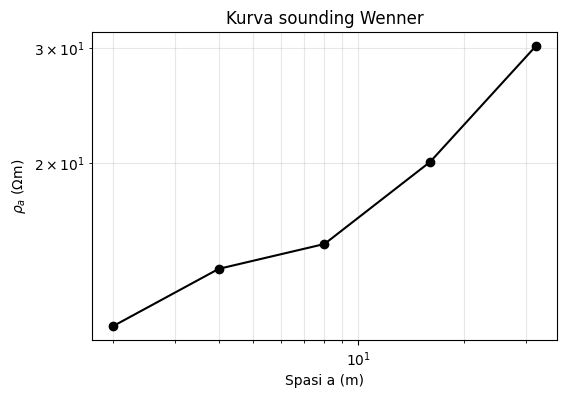

In [9]:
plt.figure(figsize=(6, 4))
plt.loglog(a, rho_a, "ko-")
plt.xlabel("Spasi a (m)"); plt.ylabel(r"$\rho_a$ ($\Omega$m)")
plt.title("Kurva sounding Wenner"); plt.grid(True, which="both", alpha=.3)
plt.show()

## Interpretasi geologi
Nilai $\rho_a$ naik terus dari sekitar 11 Ωm pada a = 2 m menjadi sekitar 30 Ωm pada a = 32 m, dan kenaikannya belum mendatar. Pola ini mengindikasikan lapisan permukaan yang relatif konduktif (resistivitas rendah, mungkin tanah lembap, lempung, atau zona jenuh air) di atas lapisan yang lebih resistif di bawahnya. Kurva belum mencapai plateau, jadi nilai resistivitas lapisan bawah yang sebenarnya belum bisa dipastikan, dan jumlah lapisan hanya bisa diperkirakan minimal dua. Semua nilai masih dalam rentang tanah, lempung, dan batuan sedimen lapuk, sehingga tidak ada indikasi batuan segar yang sangat resistif.

## Verifikasi

In [10]:
# Hitung ulang K untuk 2 baris (manual)
assert np.isclose(2 * np.pi * 2, K[0]) and np.isclose(2 * np.pi * 16, K[3])
# Konversi satuan: dV/I dalam V/A sama dengan mV/mA
assert np.allclose(R, dV / I)
# Rentang wajar tanah/batuan sedimen: 1 - 1000 ohm.m
assert np.all((rho_a > 1) & (rho_a < 1000))
print("K = 2*pi*a benar, satuan konsisten, rho_a dalam rentang wajar: OK")
print("Pola kurva: ", "naik" if np.all(np.diff(rho_a) > 0) else "tidak monoton")

K = 2*pi*a benar, satuan konsisten, rho_a dalam rentang wajar: OK
Pola kurva:  naik


---
# Kasus 4: Well Logging dengan Persamaan Archie

## Ringkasan masalah
Hitung porositas dari log densitas, lalu saturasi air (Sw) dan saturasi hidrokarbon (Sh) pada reservoir batupasir bersih.

## Asumsi
- Batupasir bersih (tanpa shale), jadi tidak ada koreksi shale.
- Tidak ada koreksi lubang bor atau invasi lumpur. Rt dianggap resistivitas formasi sebenarnya.
- Pori hanya terisi air formasi dan hidrokarbon.

## Rumus
- $\phi = \dfrac{\rho_{ma} - \rho_b}{\rho_{ma} - \rho_f}$
- $S_w = \left(\dfrac{a\,R_w}{\phi^m R_t}\right)^{1/n}$
- $S_h = 1 - S_w$

In [11]:
rho_b, rho_ma, rho_f = 2.30, 2.65, 1.00   # g/cm3
Rt, Rw = 20.0, 0.05                       # ohm.m
a_, m_, n_ = 1.0, 2.0, 2.0

phi = (rho_ma - rho_b) / (rho_ma - rho_f)
Sw = (a_ * Rw / (phi**m_ * Rt)) ** (1 / n_)
Sh = 1 - Sw

hasil4 = pd.DataFrame({
    "Besaran": ["Porositas (phi)", "Saturasi air (Sw)", "Saturasi hidrokarbon (Sh)"],
    "Desimal": [phi, Sw, Sh],
    "Persen":  [phi * 100, Sw * 100, Sh * 100],
})
hasil4.style.format({"Desimal": "{:.4f}", "Persen": "{:.2f}"}).hide(axis="index")

Besaran,Desimal,Persen
Porositas (phi),0.2121,21.21
Saturasi air (Sw),0.2357,23.57
Saturasi hidrokarbon (Sh),0.7643,76.43


## Interpretasi
Porositas sekitar 21% termasuk baik sampai sangat baik untuk reservoir batupasir. Resistivitas 20 Ωm jauh lebih tinggi dari Rw (0.05 Ωm), dan saturasi air hanya sekitar 24%, sehingga sekitar 76% pori terisi hidrokarbon. Interval ini mengindikasikan zona prospek hidrokarbon. Kesimpulan ini sah selama asumsi batupasir bersih dan Rt tanpa pengaruh invasi terpenuhi. Jika ada shale, Sw dari Archie cenderung terlalu tinggi.

## Verifikasi

In [12]:
assert 0 <= Sw <= 1 and 0 <= Sh <= 1 and np.isclose(Sw + Sh, 1)
assert 0.05 < phi < 0.35                      # rentang batupasir reservoir umum

# Hitung balik: dari Sw, dapatkan kembali Rt
Rt_back = a_ * Rw / (phi**m_ * Sw**n_)
print(f"Rt hitung balik = {Rt_back:.4f} ohm.m (data: {Rt} ohm.m)")
assert np.isclose(Rt_back, Rt)
print(f"Sw + Sh = {Sw + Sh:.4f}, phi = {phi:.4f}: OK")

Rt hitung balik = 20.0000 ohm.m (data: 20.0 ohm.m)
Sw + Sh = 1.0000, phi = 0.2121: OK


---
# Kasus 5: Dix, Ketebalan Lapisan, dan NMO

## Ringkasan masalah
Dari $t_0$ dan $V_{rms}$ dua horizon pada satu CMP, hitung kecepatan interval, ketebalan lapisan, dan koreksi NMO pada x = 1000 m di Horizon 2.

## Asumsi
- Lapisan datar horizontal, tiap lapisan homogen.
- $t_0$ adalah waktu **pulang-pergi** (two-way time), sehingga kedalaman memakai faktor ½.
- NMO dihitung dengan persamaan hiperbola penuh, bukan pendekatan orde kecil.

## Rumus
- Dix: $V_{int,n} = \sqrt{\dfrac{V_{rms,n}^2\,t_n - V_{rms,n-1}^2\,t_{n-1}}{t_n - t_{n-1}}}$
- Ketebalan: $h_n = V_{int,n}\,\dfrac{t_n - t_{n-1}}{2}$
- NMO: $t(x) = \sqrt{t_0^2 + x^2 / V_{rms}^2}$, $\Delta t_{NMO} = t(x) - t_0$

In [13]:
t0 = np.array([0.400, 0.900])        # s (TWT)
Vrms = np.array([2000.0, 2400.0])    # m/s
x_off = 1000.0                       # m

V_int = np.zeros(2)
V_int[0] = Vrms[0]                   # lapisan 1: V_int = V_rms horizon 1
V_int[1] = np.sqrt((Vrms[1]**2 * t0[1] - Vrms[0]**2 * t0[0]) / (t0[1] - t0[0]))

dt_twt = np.array([t0[0], t0[1] - t0[0]])
h = V_int * dt_twt / 2               # faktor 1/2: TWT -> one-way

t_x = np.sqrt(t0[1]**2 + x_off**2 / Vrms[1]**2)
dt_nmo = t_x - t0[1]

hasil5 = pd.DataFrame({
    "Lapisan": [1, 2],
    "V_int (m/s)": V_int,
    "Ketebalan (m)": h,
})
display(hasil5.style.format({"V_int (m/s)": "{:.1f}", "Ketebalan (m)": "{:.1f}"}).hide(axis="index"))
print(f"t(x=1000 m) Horizon 2 = {t_x:.4f} s")
print(f"Delta t NMO           = {dt_nmo:.4f} s  ({dt_nmo*1000:.1f} ms)")

Lapisan,V_int (m/s),Ketebalan (m)
1,2000.0,400.0
2,2677.3,669.3


t(x=1000 m) Horizon 2 = 0.9918 s
Delta t NMO           = 0.0918 s  (91.8 ms)


## Interpretasi
Kecepatan interval naik dari 2000 m/s di lapisan 1 menjadi sekitar 2677 m/s di lapisan 2, kontras sekitar 34%. Kenaikan ini wajar secara geologi, sebab kompaksi dan pengurangan porositas membuat kecepatan bertambah terhadap kedalaman, dan nilainya cocok dengan sedimen klastik terkompaksi seperti batupasir atau serpih. Kontras kecepatan yang cukup besar ini juga menghasilkan koefisien refleksi yang terdeteksi pada Horizon 2.

## Verifikasi

In [14]:
# 1. Konversi TWT -> one-way (kedalaman memakai t/2)
assert np.isclose(h[0], Vrms[0] * t0[0] / 2)

# 2. V_int lapisan 1 = V_rms horizon 1 (satu lapisan homogen, rms = interval)
assert np.isclose(V_int[0], Vrms[0])

# 3. Kedalaman total: jumlah ketebalan vs V_rms * t/2
z_sum = h.sum()
z_rms = Vrms[1] * t0[1] / 2
V_avg = z_sum / (t0[1] / 2)
print(f"Jumlah ketebalan      = {z_sum:.1f} m")
print(f"Kedalaman via V_rms   = {z_rms:.1f} m  (selisih {z_rms - z_sum:.1f} m)")
print(f"Kecepatan rata-rata   = {V_avg:.1f} m/s  (< V_rms = {Vrms[1]:.0f} m/s)")

# 4. dt_NMO positif dan lebih kecil dari t0
assert 0 < dt_nmo < t0[1]
print("dt_NMO positif dan < t0: OK")

Jumlah ketebalan      = 1069.3 m
Kedalaman via V_rms   = 1080.0 m  (selisih 10.7 m)
Kecepatan rata-rata   = 2376.3 m/s  (< V_rms = 2400 m/s)
dt_NMO positif dan < t0: OK


Kedalaman via $V_{rms}$ sedikit lebih besar daripada jumlah ketebalan karena $V_{rms}$ selalu lebih besar atau sama dengan kecepatan rata-rata (bobotnya pada kuadrat kecepatan). Jadi $V_{rms} \cdot t/2$ memberi estimasi kedalaman yang sedikit berlebih. Jumlah ketebalan dari Dix adalah nilai yang benar untuk model ini.